In [1]:
%load_ext autoreload
%autoreload 2

import pandas as pd

from src.config import load_yaml_config
from src.data import load_data_from_json
from src.cleaning import clean_dataset
from src.preprocessing import add_rain_event, prepare_city_stream
from src.evaluation import run_experiments, save_results
from src.latex import print_latex_results_tables

def get_fresh_dataframes_and_config() -> (dict, pd.DataFrame, pd.DataFrame):
    """Loads a fresh config and fresh, cleaned dataframes for both cities in order to avoid issues with notebook usage."""
    # Load the config
    config = load_yaml_config()
    
    # Load the datasets
    df_raw_lisboa = load_data_from_json(config["data"], "Lisboa")
    df_raw_porto = load_data_from_json(config["data"], "Porto")
    
    # Clean the datasets
    df_cleaned_lisboa = clean_dataset(config["cleaning"], df_raw_lisboa)
    df_cleaned_porto = clean_dataset(config["cleaning"], df_raw_porto)
    
    # Add the rain event columns
    add_rain_event(df_cleaned_lisboa)
    add_rain_event(df_cleaned_porto)

    return config, df_cleaned_lisboa, df_cleaned_porto

# Exploratory Data Analysis

In [ ]:
config, df_lisboa, df_porto = get_fresh_dataframes_and_config()

### City A: Lisboa

### City B: Porto

# Comparative Data Analysis

In [19]:
config, df_lisboa, df_porto = get_fresh_dataframes_and_config()

Calculate $\mathrm{std}(R_m)$:

In [29]:
print(f"Lisboa: {df_lisboa.set_index("time")["rain_event"].resample("MS").mean().mul(100).std():.1f}")
print(f"Porto: {df_porto.set_index("time")["rain_event"].resample("MS").mean().mul(100).std():.1f}")

Lisboa: 9.3
Porto: 12.7


Calculate $\mathbb{E}\left[C^{(24)}_t \mid C^{(24)}_t > 0\right]$:

In [30]:
df_lisboa["rainy_hours_previous_24h"] = df_lisboa["rain_event"].shift(1).rolling(window=24, min_periods=24).sum()
df_porto["rainy_hours_previous_24h"] = df_porto["rain_event"].shift(1).rolling(window=24, min_periods=24).sum()

print(f"Lisboa: {df_lisboa.loc[df_lisboa["rainy_hours_previous_24h"] > 0, "rainy_hours_previous_24h"].mean():.1f}")
print(f"Porto: {df_porto.loc[df_porto["rainy_hours_previous_24h"] > 0, "rainy_hours_previous_24h"].mean():.1f}")

Lisboa: 7.1
Porto: 10.3


Calculate $\mathrm{median}\left((B_i)_{i=1}^b \right)$ and $\mathrm{median}\left((D_i)_{i=1}^d \right)$:

In [32]:
def calculate_rainy_and_dry_period_median(df: pd.DataFrame) -> (int, int):
    # Creates a new group whenever rain_event changes:
    # rain_event:  0 0 0 1 1 0 1 1 1
    # group_id:    1 1 1 2 2 3 4 4 4
    group_id = (
        df["rain_event"]
        .ne(df["rain_event"].shift())
        .cumsum()
    )

    periods = (
        df.groupby(group_id)["rain_event"]
        .agg(
            event_type="first",
            duration="size"
        )
    )

    rainy_period_lengths = periods.loc[periods["event_type"] == 1, "duration"]
    dry_period_lengths = periods.loc[periods["event_type"] == 0, "duration"]

    return rainy_period_lengths.median(), dry_period_lengths.median()

lisboa_rain_median, lisboa_dry_median = calculate_rainy_and_dry_period_median(df_lisboa)
porto_rain_median, porto_dry_median = calculate_rainy_and_dry_period_median(df_porto)

print(f"Lisboa median rainy period: {lisboa_rain_median}")
print(f"Lisboa median dry period: {lisboa_dry_median}")

print(f"Porto median rainy period: {porto_rain_median}")
print(f"Porto median dry period: {porto_dry_median}")

Lisboa median rainy period: 2.0
Lisboa median dry period: 4.0
Porto median rainy period: 3.0
Porto median dry period: 3.0


# Data Stream Mining Experiment

In [2]:
config, df_lisboa, df_porto = get_fresh_dataframes_and_config()

# Prepare the data streams
lisboa_stream = prepare_city_stream(config["preprocessing"], df_lisboa)
porto_stream = prepare_city_stream(config["preprocessing"], df_porto)
streams = {"Lisboa": lisboa_stream, "Porto": porto_stream}

# Run the experiment and save the results
summary, history = run_experiments(config, streams)
save_results(config, summary, history, out_dir="results")

print(summary)

Lisboa / A / gaussian_naive_bayes: Accuracy=0.921, Macro-F1=0.751, Recall=0.402
Lisboa / A / online_logistic_regression: Accuracy=0.925, Macro-F1=0.774, Recall=0.457
Lisboa / A / hoeffding_tree: Accuracy=0.934, Macro-F1=0.836, Recall=0.678
Lisboa / A / online_bagging: Accuracy=0.935, Macro-F1=0.842, Recall=0.710
Lisboa / A / adaptive_random_forest: Accuracy=0.926, Macro-F1=0.799, Recall=0.557
Lisboa / B / gaussian_naive_bayes: Accuracy=0.915, Macro-F1=0.771, Recall=0.512
Lisboa / B / online_logistic_regression: Accuracy=0.927, Macro-F1=0.793, Recall=0.517
Lisboa / B / hoeffding_tree: Accuracy=0.932, Macro-F1=0.838, Recall=0.710
Lisboa / B / online_bagging: Accuracy=0.935, Macro-F1=0.841, Recall=0.709
Lisboa / B / adaptive_random_forest: Accuracy=0.922, Macro-F1=0.790, Recall=0.543
Porto / A / gaussian_naive_bayes: Accuracy=0.892, Macro-F1=0.794, Recall=0.508
Porto / A / online_logistic_regression: Accuracy=0.904, Macro-F1=0.827, Recall=0.597
Porto / A / hoeffding_tree: Accuracy=0.922, 

In [3]:
print_latex_results_tables(summary)

\begin{table}[htbp]
    \centering
    \caption
    {
        Predictive and computational performance for Representation A.
        Predictive metrics are reported as percentages.
        Each cell reports
        \colorbox{LisboaGreen!70}{\scriptsize Lisboa}
        in the top-left triangle and
        \colorbox{PortoRed!70}{\scriptsize Porto}
        in the bottom-right triangle.
    }
    \label{tab:representation-a-results}

    \resizebox{\textwidth}{!}{%
        \begin{tabularx}{0.98\textwidth}{@{}Y C{1.55cm} C{1.55cm} C{1.55cm} C{1.55cm} C{1.55cm} C{1.55cm}@{}}
            \toprule
            \textbf{Model}
            & \textbf{Acc.}
            & \textbf{Macro-F1}
            & \textbf{Prec.}
            & \textbf{Recall}
            & \textbf{Pred. ms/event}
            & \textbf{Update ms/event} \\
            \midrule
            GaussianNB & \splitcell{92.1}{89.2} & \splitcell{75.1}{79.4} & \splitcell{84.8}{90.8} & \splitcell{40.2}{50.8} & \splitcell{0.052}{0.052} & \spl

'\\begin{table}[htbp]\n    \\centering\n    \\caption\n    {\n        Predictive and computational performance for Representation A.\n        Predictive metrics are reported as percentages.\n        Each cell reports\n        \\colorbox{LisboaGreen!70}{\\scriptsize Lisboa}\n        in the top-left triangle and\n        \\colorbox{PortoRed!70}{\\scriptsize Porto}\n        in the bottom-right triangle.\n    }\n    \\label{tab:representation-a-results}\n\n    \\resizebox{\\textwidth}{!}{%\n        \\begin{tabularx}{0.98\\textwidth}{@{}Y C{1.55cm} C{1.55cm} C{1.55cm} C{1.55cm} C{1.55cm} C{1.55cm}@{}}\n            \\toprule\n            \\textbf{Model}\n            & \\textbf{Acc.}\n            & \\textbf{Macro-F1}\n            & \\textbf{Prec.}\n            & \\textbf{Recall}\n            & \\textbf{Pred. ms/event}\n            & \\textbf{Update ms/event} \\\\\n            \\midrule\n            GaussianNB & \\splitcell{92.1}{89.2} & \\splitcell{75.1}{79.4} & \\splitcell{84.8}{90.8} & \\sp

# Report Figures Creation

In [3]:
from src.plotting import plot_R_m, plot_C_24, plot_city_comparison

plotting_config = config["plotting"]

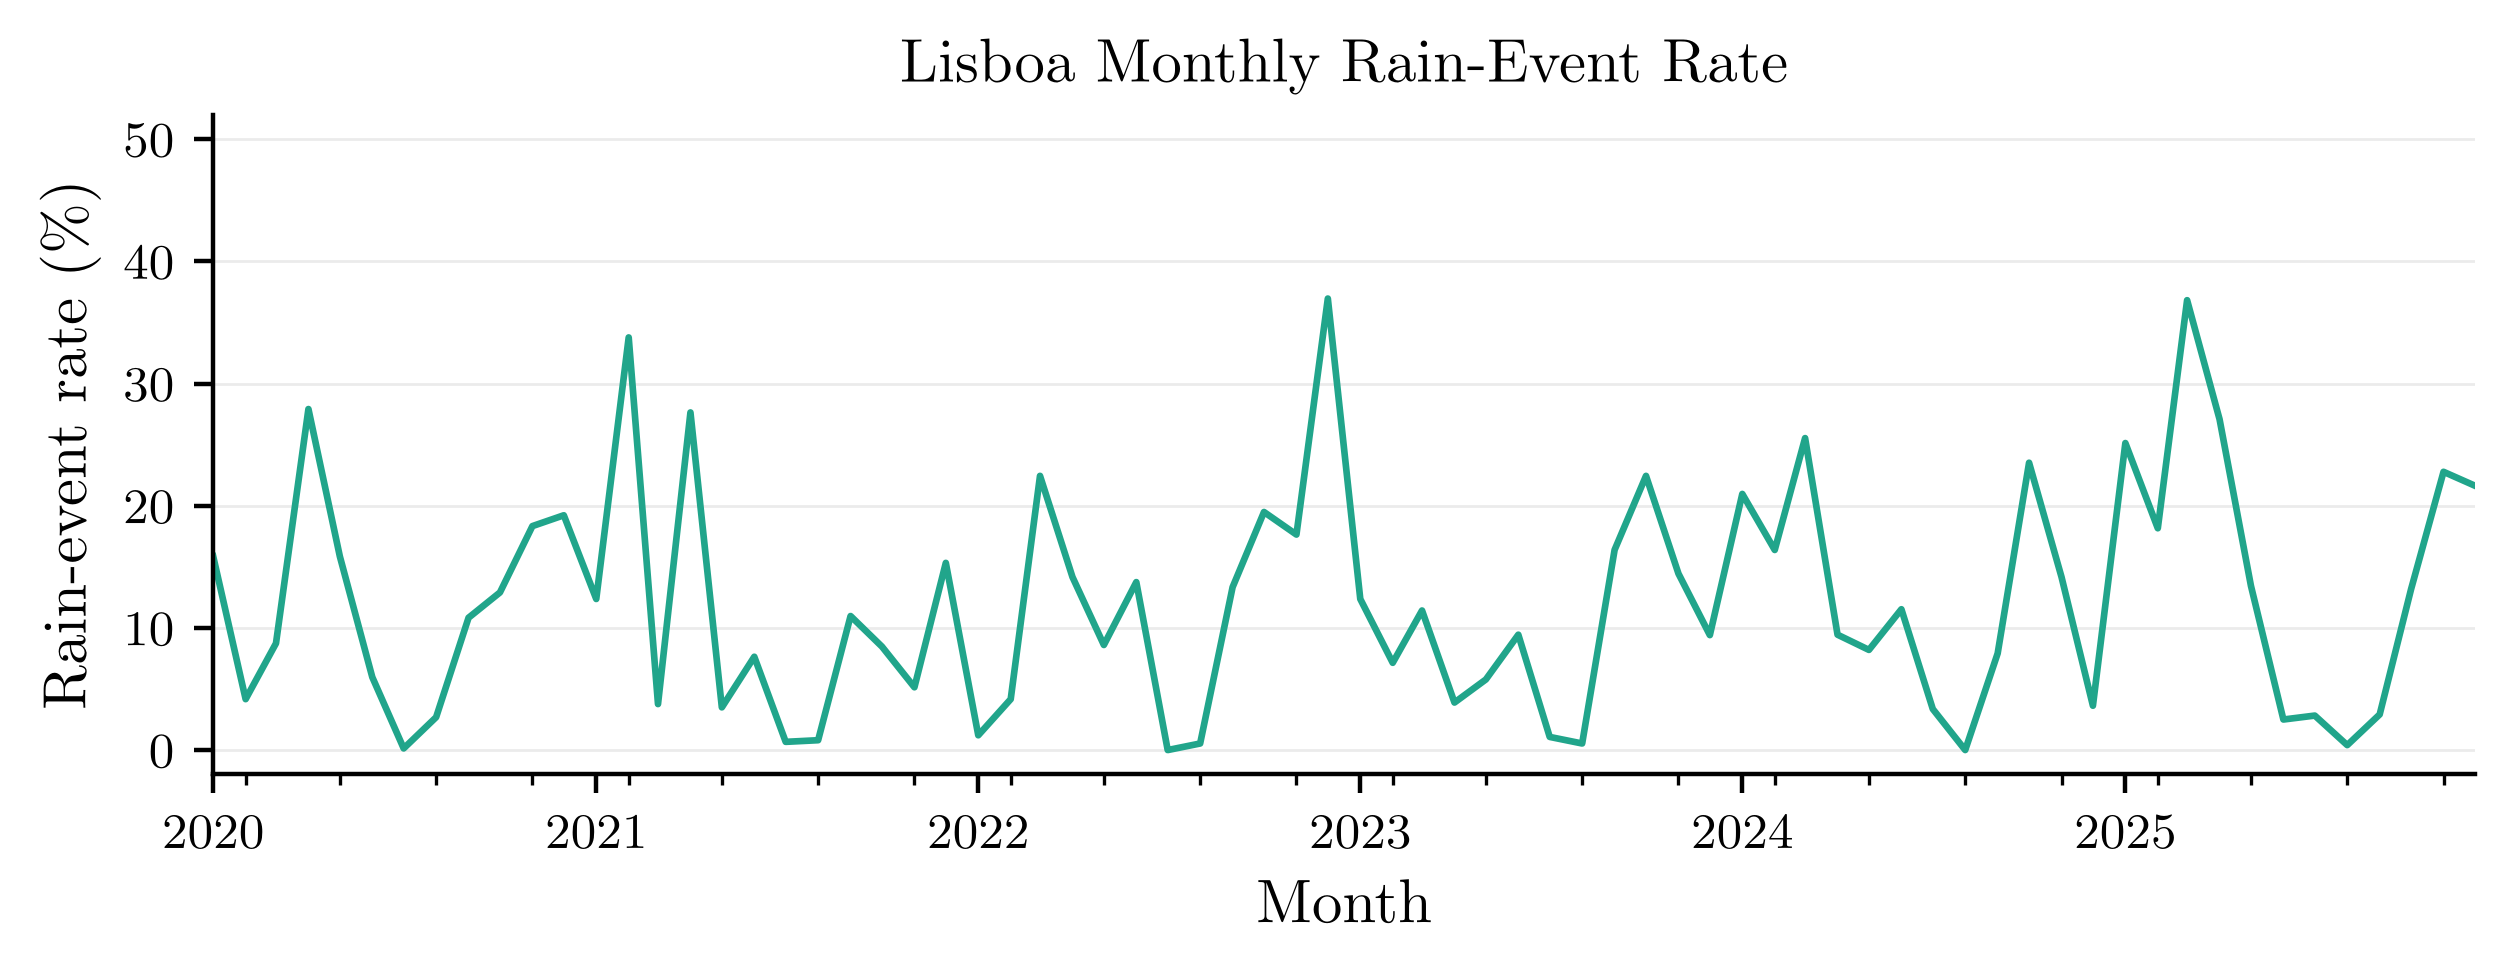

Saved B:\Documents\Uni\Data Stream Mining\Assignments\Practical Assignment 1\temp\Lisboa_R_m_rg45yes4.pdf


In [4]:
plot_R_m(plotting_config, df_cleaned_lisboa, "Lisboa")

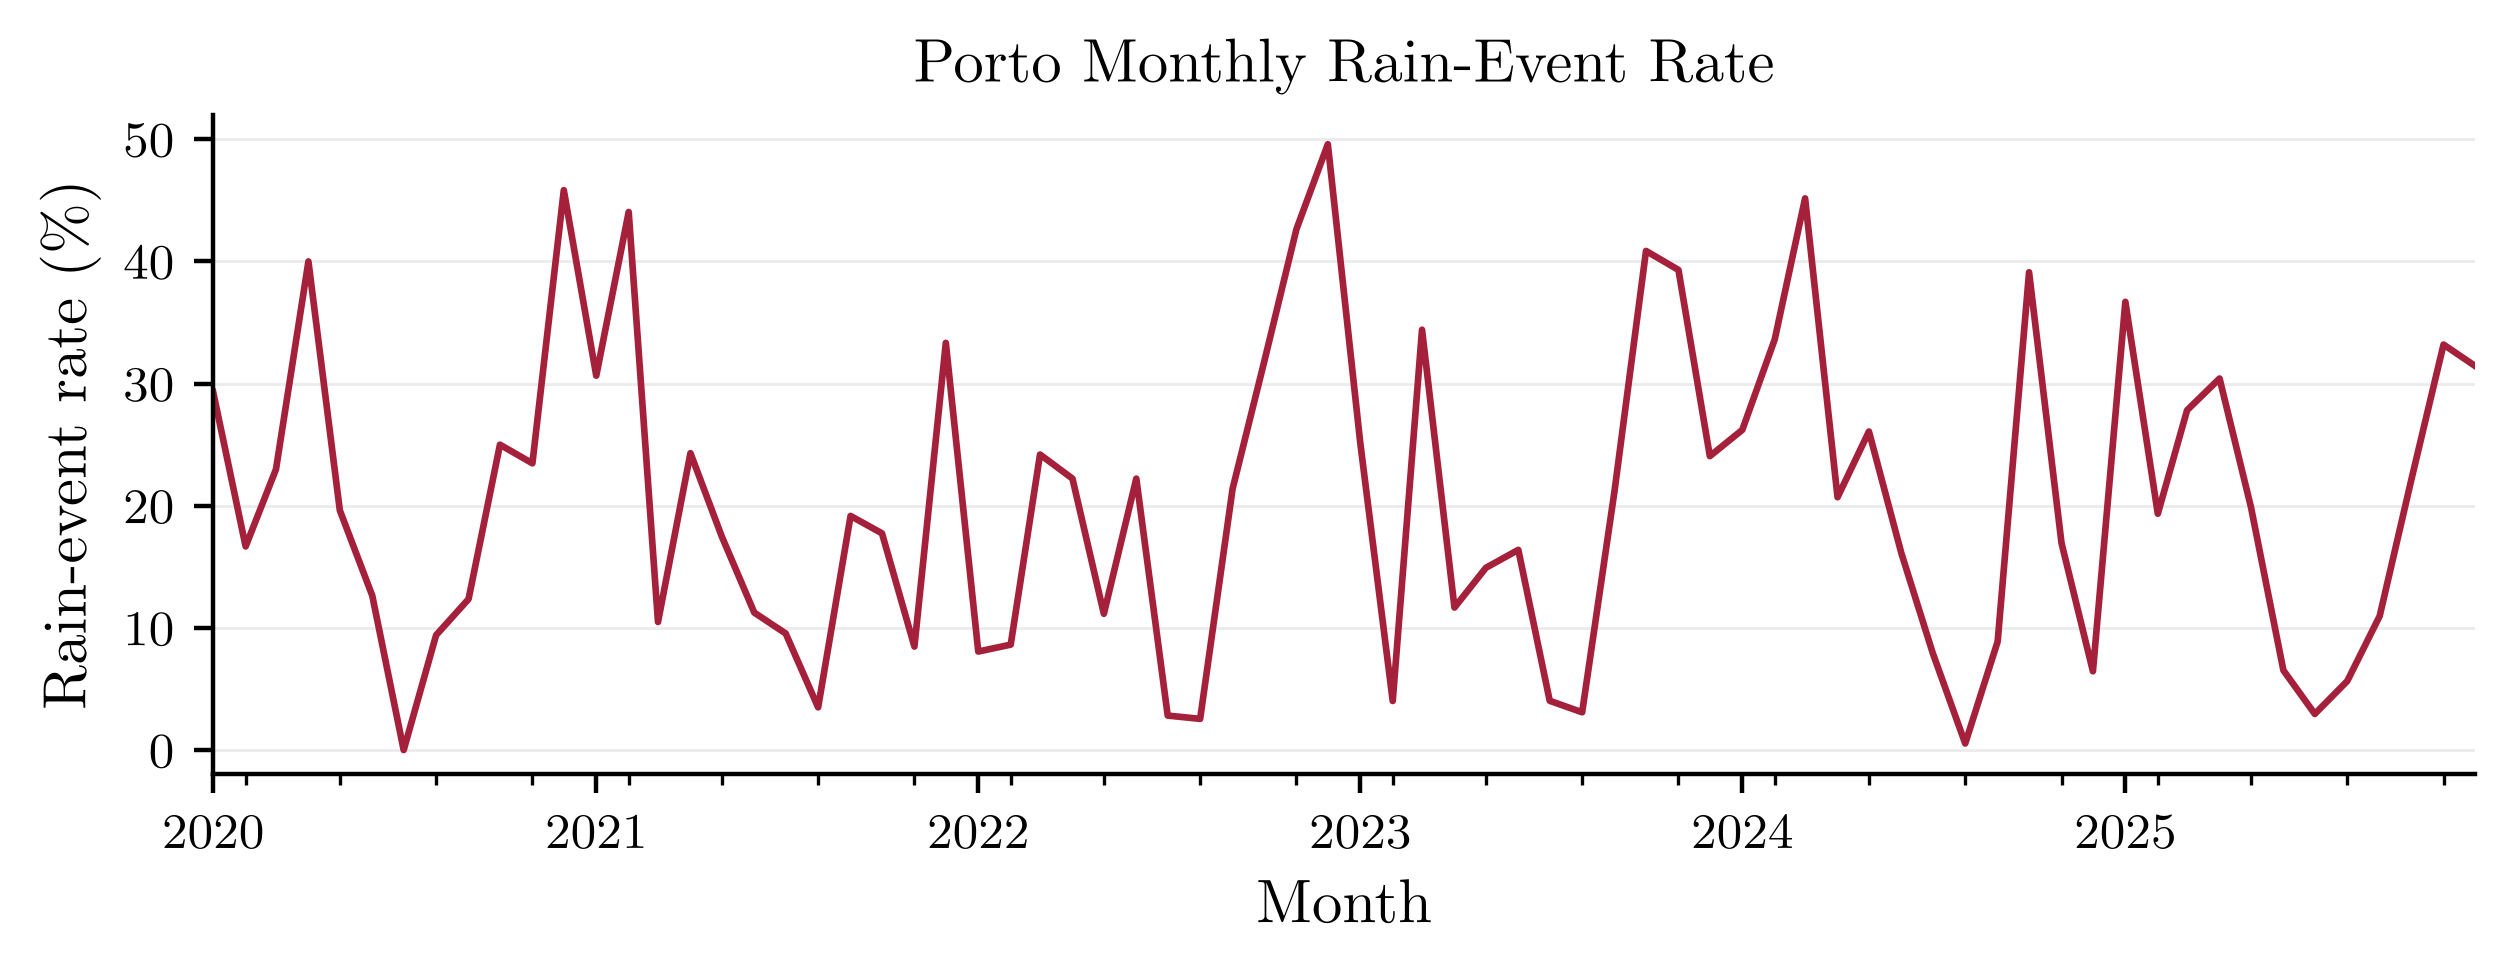

Saved B:\Documents\Uni\Data Stream Mining\Assignments\Practical Assignment 1\temp\Porto_R_m_crgkblzs.pdf


In [5]:
plot_R_m(plotting_config, df_cleaned_porto, "Porto")

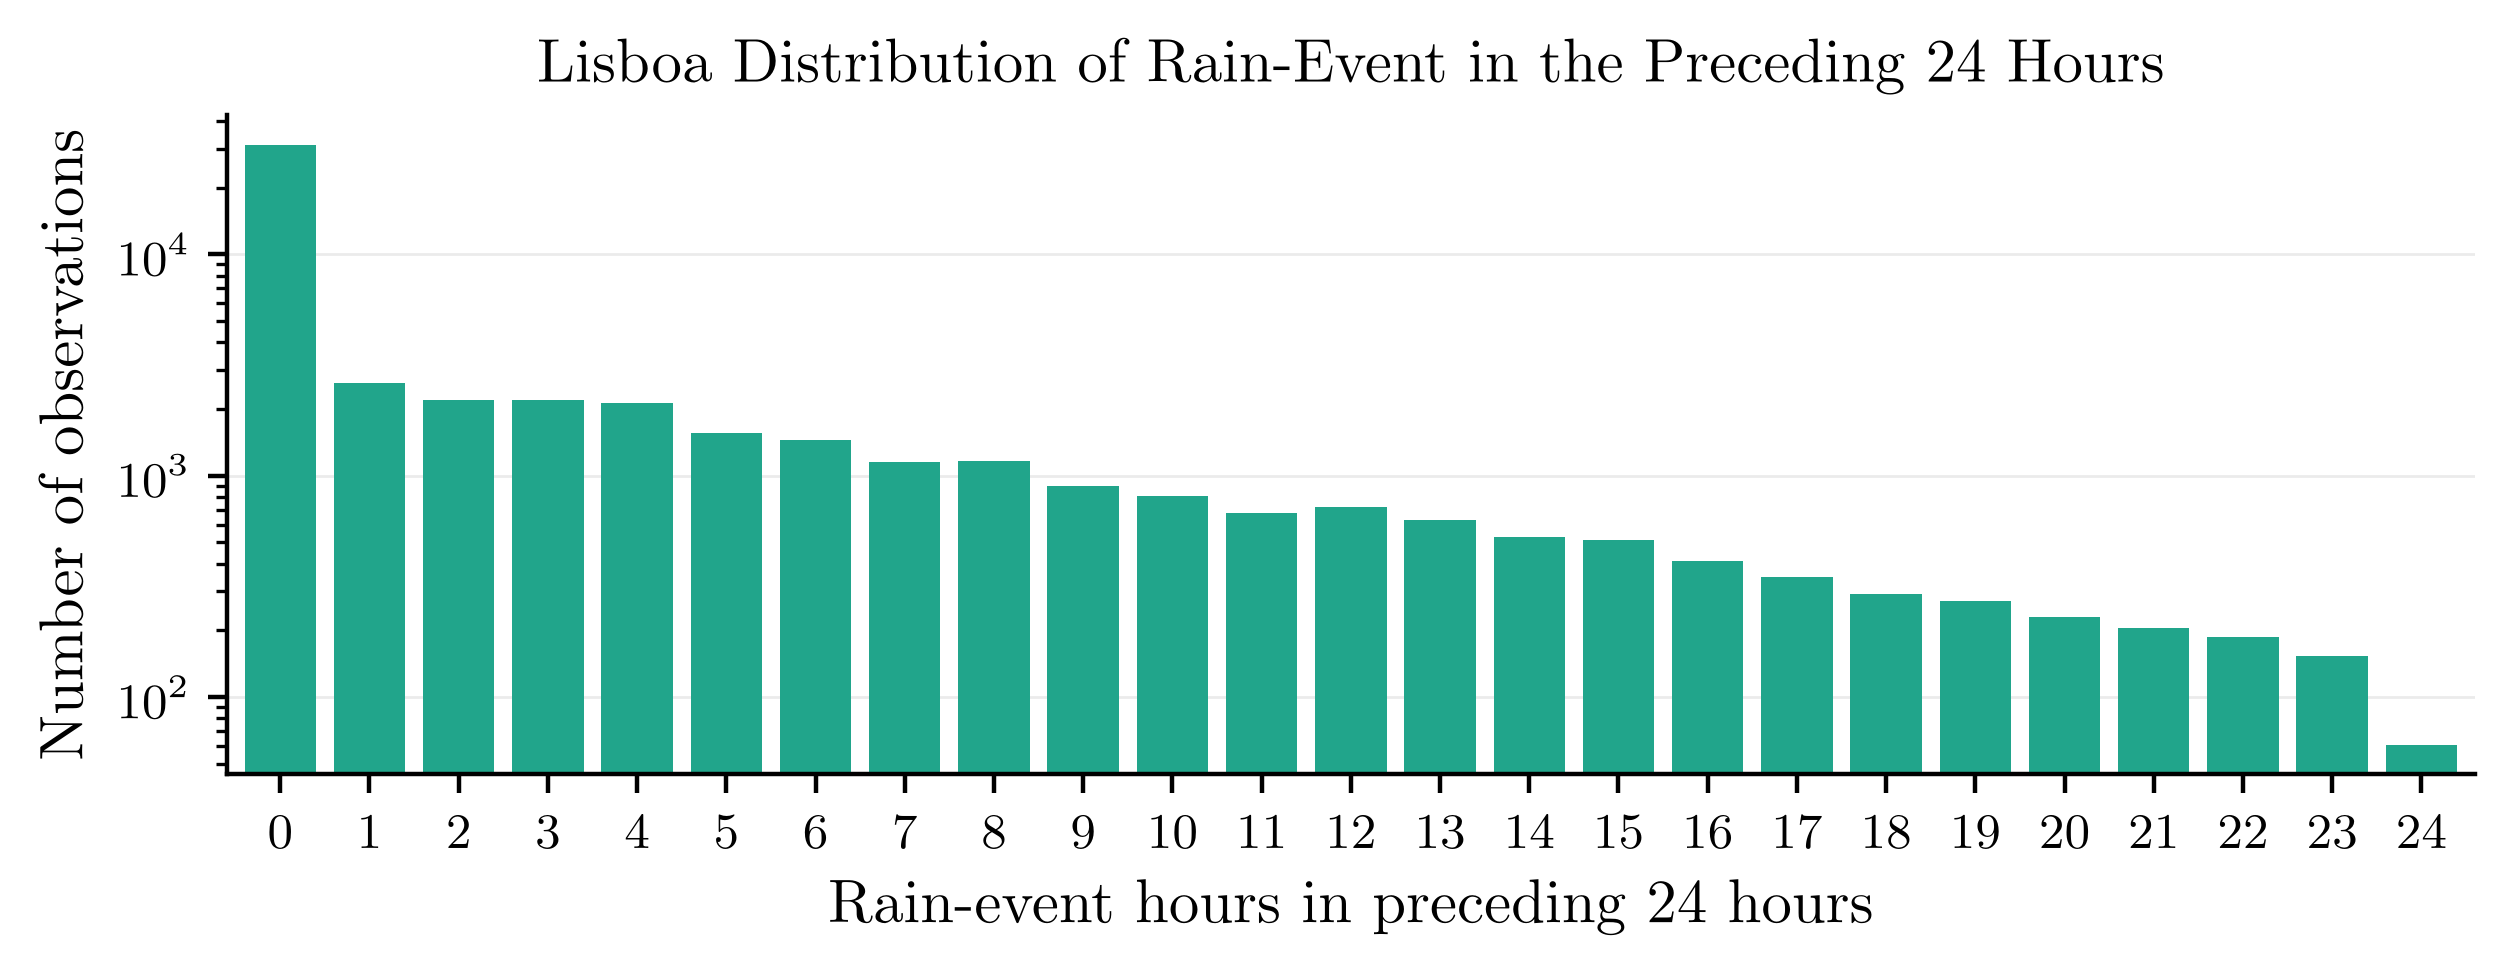

Saved B:\Documents\Uni\Data Stream Mining\Assignments\Practical Assignment 1\temp\Lisboa_C_24_ct4h8v72.pdf


In [6]:
plot_C_24(plotting_config, df_cleaned_lisboa, "Lisboa")

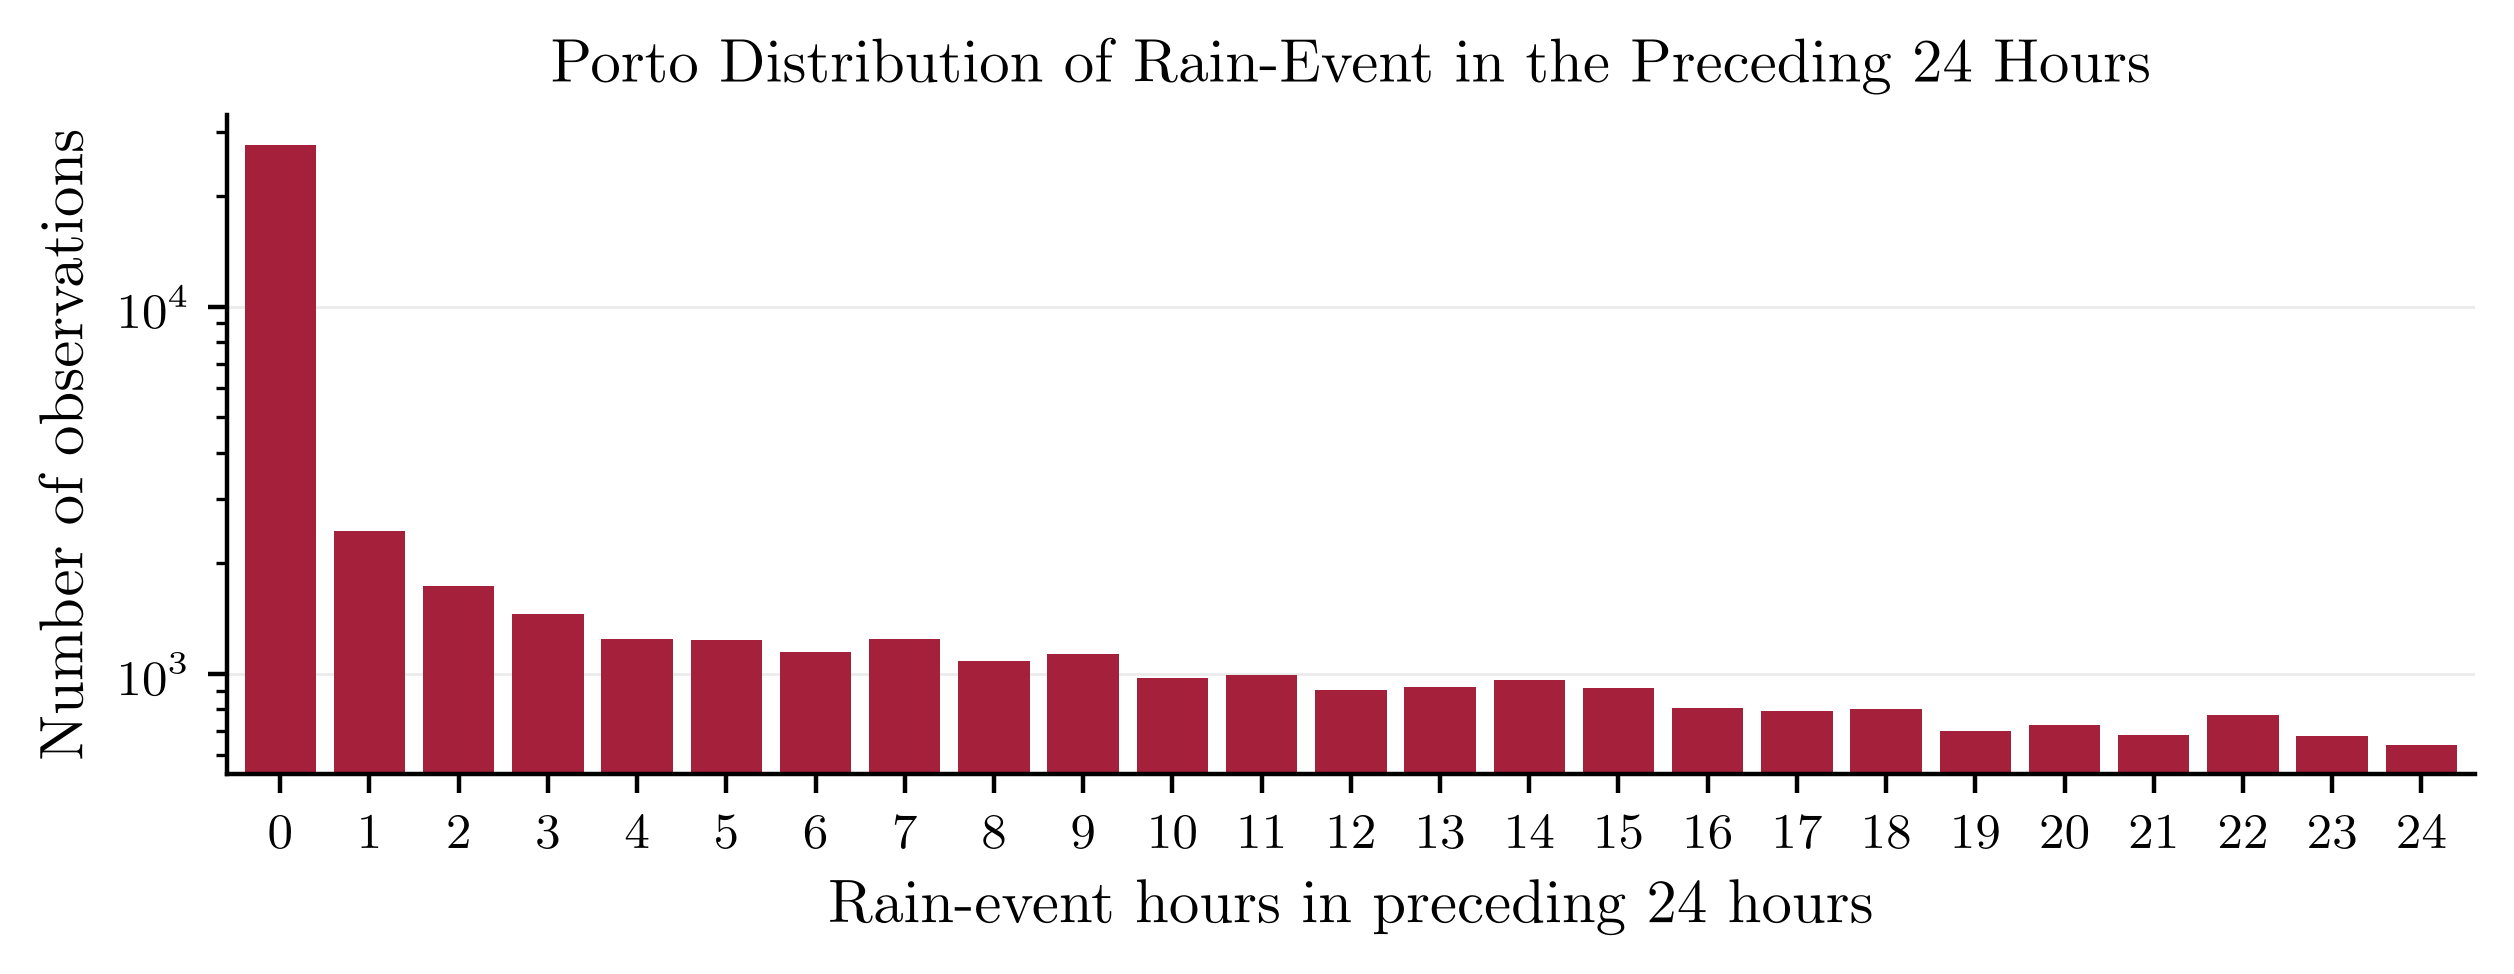

Saved B:\Documents\Uni\Data Stream Mining\Assignments\Practical Assignment 1\temp\Porto_C_24_4gzizosq.pdf


In [7]:
plot_C_24(plotting_config, df_cleaned_porto, "Porto")

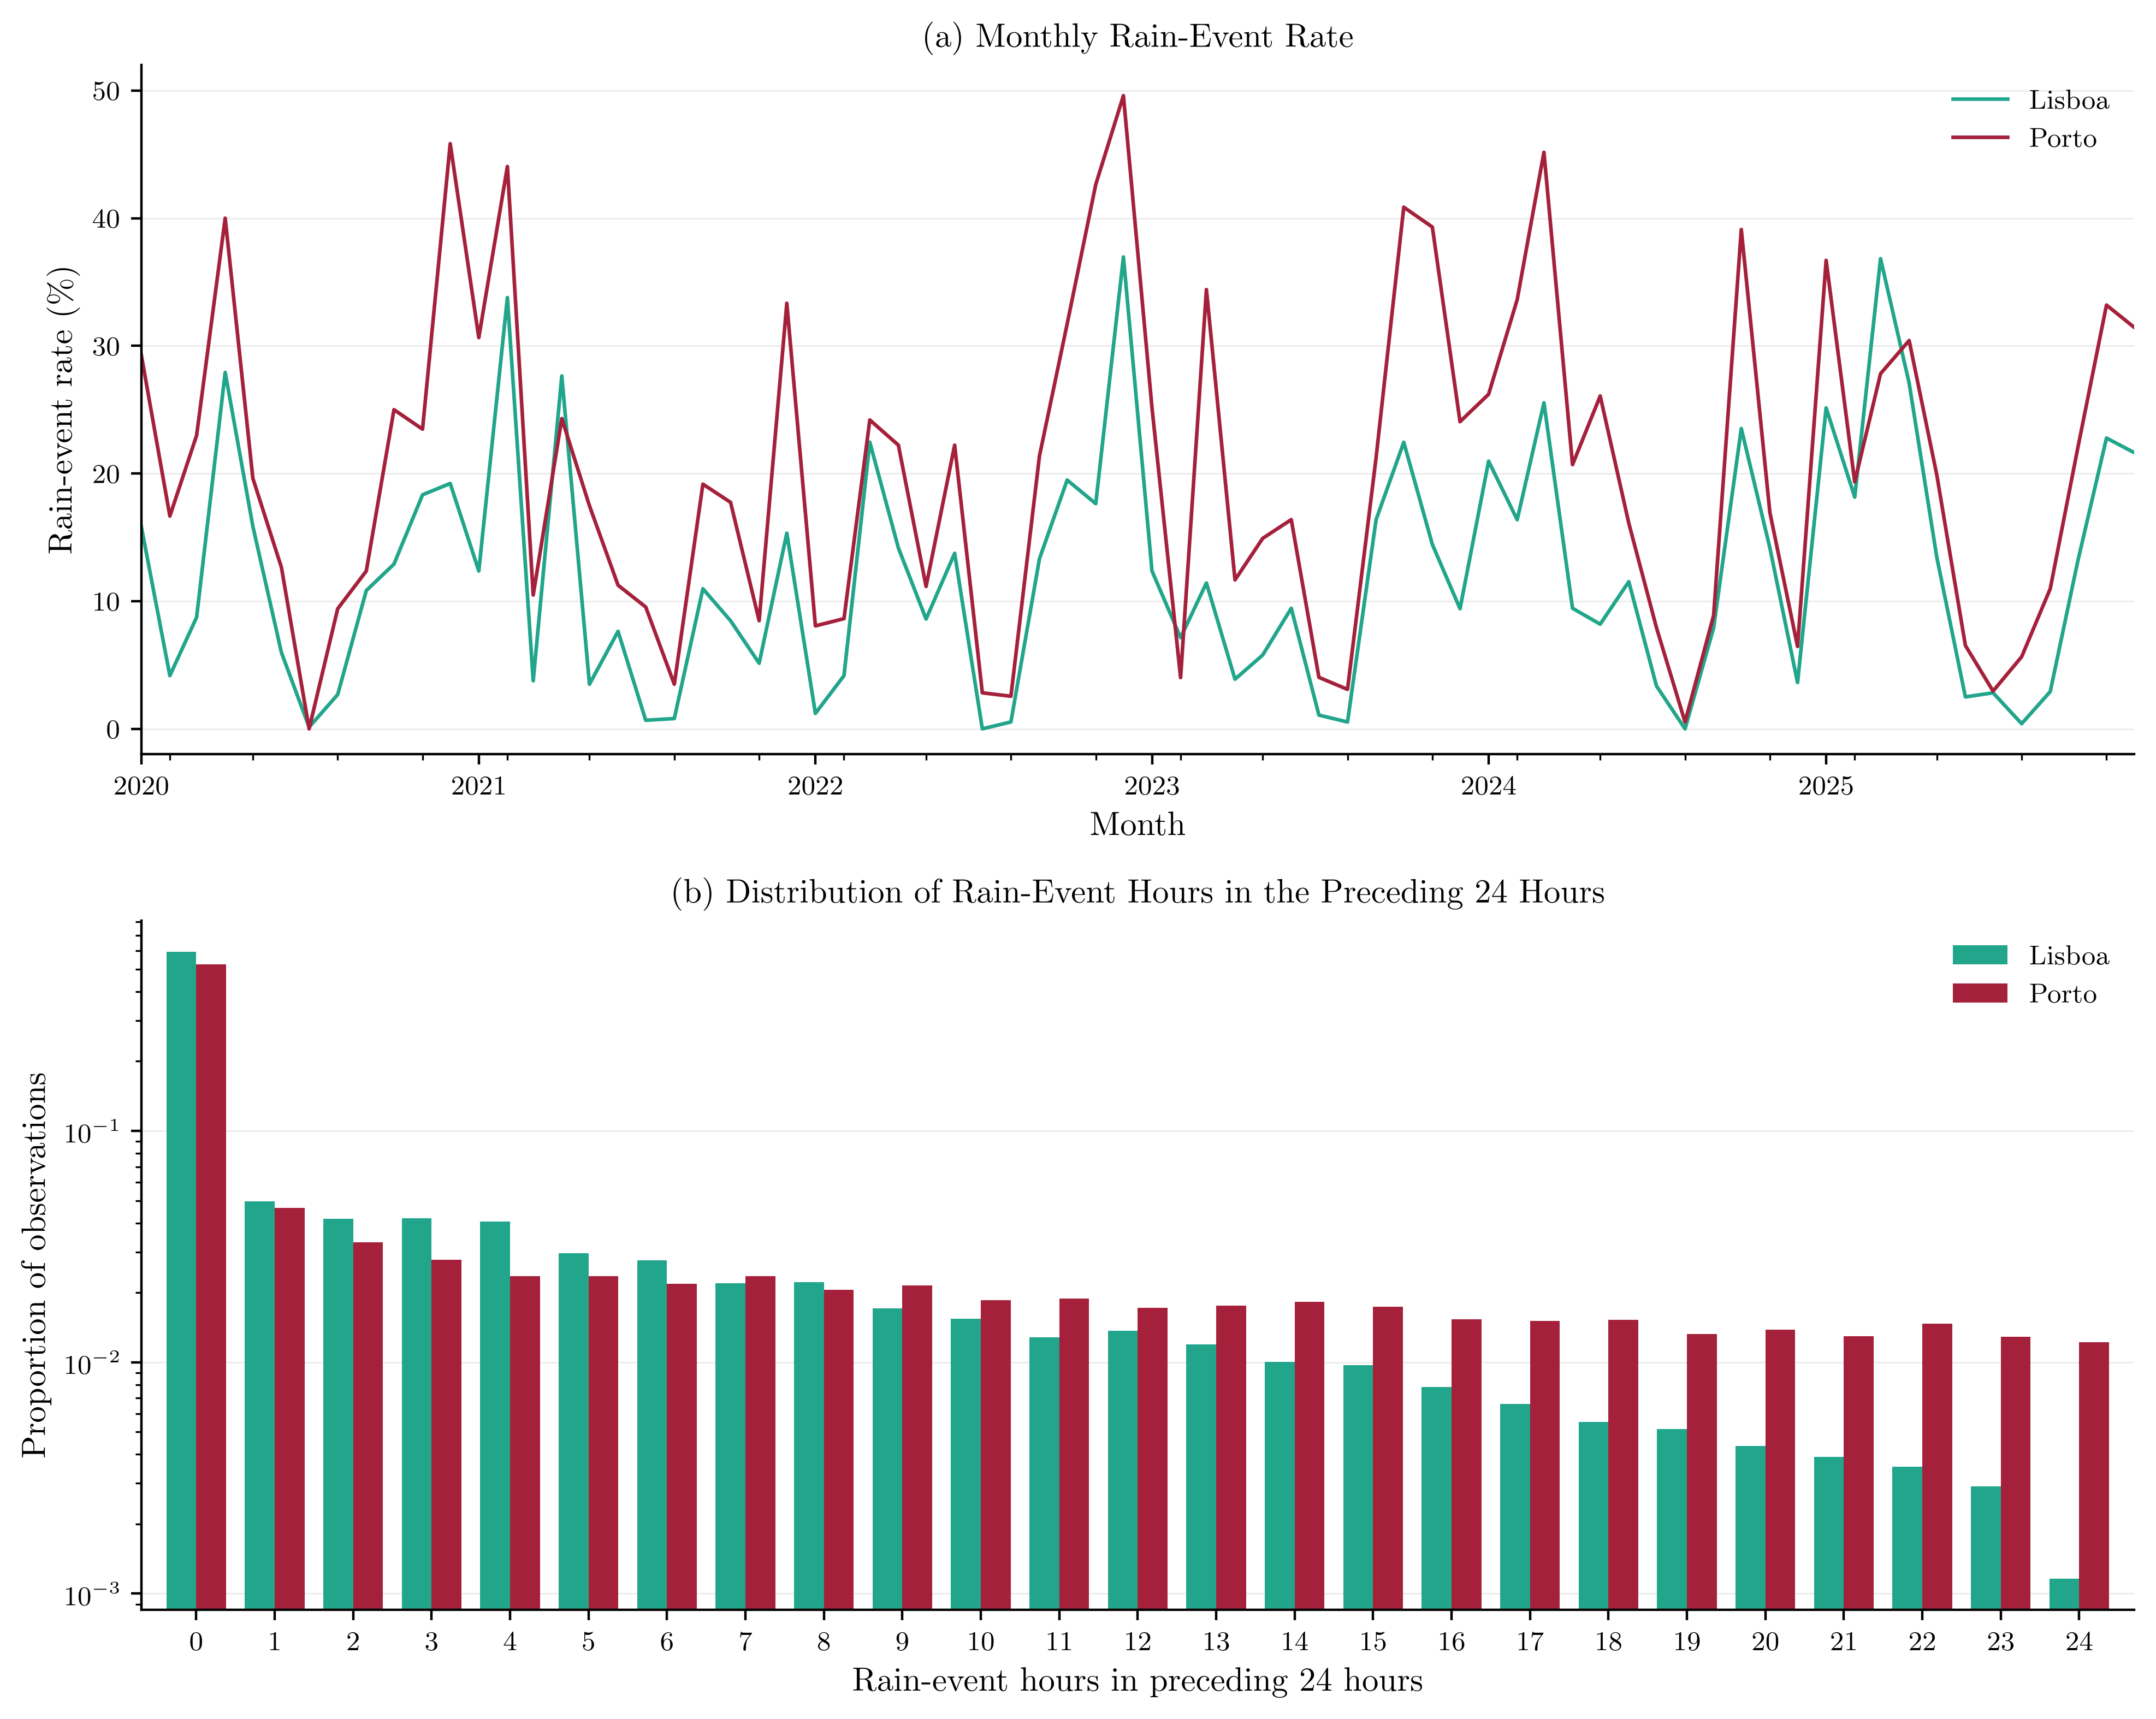

Saved B:\Documents\Uni\Data Stream Mining\Assignments\Practical Assignment 1\temp\city_comparison_swjy43ai.pdf


In [8]:
plot_city_comparison(plotting_config, df_cleaned_lisboa, df_cleaned_porto)